# Compulsory Assignment 4: Variational Autoencoders

Please fill out the group name, number, members and optionally the name below.

**Group number**: 19\
**Group member 1**: Matthieu Jouyit \
**Group member 2**: Paul-Adrien Lu-Yen-Tung \
**Group member 3**: Emre Can Emer \
**Group name (optional)**:

# Assignment Submission
To complete this assignment answer the relevant questions in this notebook and write the code required to implement the relevant models. It consists of **<u>two tasks</u>**. At the end of each task, there are discussion questions that _must_ be answered. The assignment is submitted by handing in this notebook as an .ipynb file and as a .pdf file.

We will explore how to use autoencoder networks using the **Fashion-MNIST** dataset. Fashion-MNIST is a dataset of Zalando's article images, designed as a drop-in replacement for the original MNIST dataset of handwritten digits. It has exactly the same format as MNIST: 70,000 grayscale images of 28x28 pixels, split into 60,000 training examples and 10,000 testing examples. Instead of a digit, each image shows a piece of clothing from one of 10 classes:

| Label | Class | Label | Class |
|---|---|---|---|
| 0 | T-shirt/top | 5 | Sandal |
| 1 | Trouser | 6 | Shirt |
| 2 | Pullover | 7 | Sneaker |
| 3 | Dress | 8 | Bag |
| 4 | Coat | 9 | Ankle boot |

Fashion-MNIST is harder than MNIST: the images contain more texture and detail, and several classes (e.g. T-shirt/top, Pullover, Coat and Shirt) look very similar.

Autoencoder is an introduction to encoder-decoder architecture. Here we will use an encoder to transform the data into a latent representation, and a decoder to project it back into the visual space.
Two main components: an **encoder** and a **decoder**.
 - The encoder takes in the input data and maps it to a lower-dimensional latent representation. It typically consists of multiple layers that gradually reduce the dimensionality of the input data, capturing its essential features. The output of the encoder is a compressed representation of the input, often referred to as a code or latent vector.
 - The decoder, on the other hand, takes the code from the encoder and reconstructs the original data from it. It mirrors the architecture of the encoder by gradually expanding the code back to the original dimensionality. The output of the decoder is a reconstruction of the input data, which ideally should closely resemble the original input.

<div>
<img src="https://tikz.net/janosh/autoencoder.png" width="300"/>
<div>

---

### **Task 1**
- Load the Fashion-MNIST dataset.
	- > (x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
	- Normalize the images to have pixel values between 0 and 1.
- Build an autoencoder model.
	- The encoder should compress the images into a lower-dimensional latent space.
	- The decoder should reconstruct the images from the latent space.
	- The intermediate layers can either be linear or convolutional.
- Train the autoencoder.
	- Use `binary-cross-entropy` loss function for _reconstruction_ (i.e. target value = input value)
	- You can choose optimizer freely (Adam is recommended).
- Visualize the reconstructed images.
	- _Compare_ original and reconstructed images.
- Visualize the latent space
	- Use PCA to visualize the 2d-latent space.
	- Use the clothing class as labels (see the table above)
- Answer the discussion questions

In [2]:
# Import necessary libraries
# Necessary Imports
import numpy as np

import tensorflow as tf
from keras.losses import binary_crossentropy
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

from tensorflow import keras
from tensorflow.keras import layers

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA

In [3]:
# 1. Load and preprocess the Fashion-MNIST dataset
# Your code here
# Load the MNIST dataset
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Data Preprocessing
## Normalize the pixel values to [0, 1] range
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

In [4]:
# Second model doesn't that flattened vectors.
x_train_2 = x_train
x_test_2 = x_test

# This is for the first model.
## Flatten the 28x28 images to a 784 vector for each image
x_train = x_train.reshape((len(x_train), int(np.prod(x_train.shape[1:]))))
x_test = x_test.reshape((len(x_test), int(np.prod(x_test.shape[1:]))))

input_dim = x_train.shape[1]  # 784, a plain Python int

### First model

We decided to include two autoencoding models here for this assignment. We worked separately on some parts of the project and our models gave us different results and performance. 

The reason for including both models is that we believe it showcases the difference between image quality and better classification and clustering.

The main difference between the models can be seen in reconstructed image quality and latent space visualization sections. The difference between the results are explained in the discussion section below.

In [5]:
# The code below for the first model are mostly taken from the teachers' lecture notes from "Generative_Models_AE_VAE" file 
# and adjusted slightly. The second model uses a custom architecture.

In [6]:
# 2. Build the autoencoder model
# Your code here

# Autoencoder Architecture
## Input layer
input_img = Input(shape=(input_dim,))
## Encoding layer
encoded = Dense(128, activation='relu')(input_img)
## Decoding layer (units must be a Python int, not numpy.int64)
decoded = Dense(input_dim, activation='sigmoid')(encoded)

# Construct the Autoencoder Model
autoencoder = Model(input_img, decoded)
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 201,616 (787.56 KB)

 Trainable params: 201,616 (787.56 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.3703 - val_loss: 0.3137
Epoch 2/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.3000 - val_loss: 0.2922
Epoch 3/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2850 - val_loss: 0.2830
Epoch 4/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2784 - val_loss: 0.2785
Epoch 5/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2748 - val_loss: 0.2755
Epoch 6/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2722 - val_loss: 0.2734
Epoch 7/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2703 - val_loss: 0.2721
Epoch 8/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2688 - val_loss: 0.2706
Epoch 9/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2677 - val_loss: 0.2694
Epoch 10/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2668 - val_loss: 0.2687
Epoch 11/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2659 - val_loss: 0.2679
Epoch 12/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step

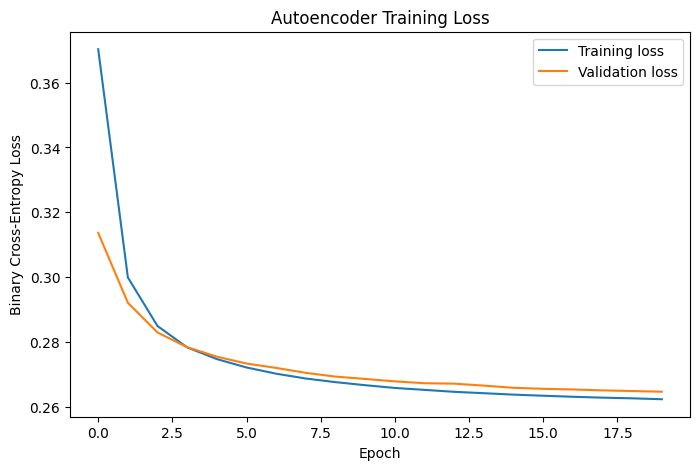

In [7]:
# 3. Compile and train the autoencoder
# Your code here

# Compile the model with binary crossentropy loss and adam optimizer
autoencoder.compile(optimizer='adam', loss=tf.keras.losses.BinaryCrossentropy())

# Train the Autoencoder
## We're using the training images both as input and target since autoencoders are unsupervised
training = autoencoder.fit(x_train, x_train,
                epochs=20,
                batch_size=256,
                shuffle=True,
                validation_data=(x_test, x_test))

# Using the trained Autoencoder to reconstruct test images
decoded_imgs = autoencoder.predict(x_test)

# Plot the training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(training.history["loss"], label="Training loss")
plt.plot(training.history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Autoencoder Training Loss")
plt.legend()
plt.show()

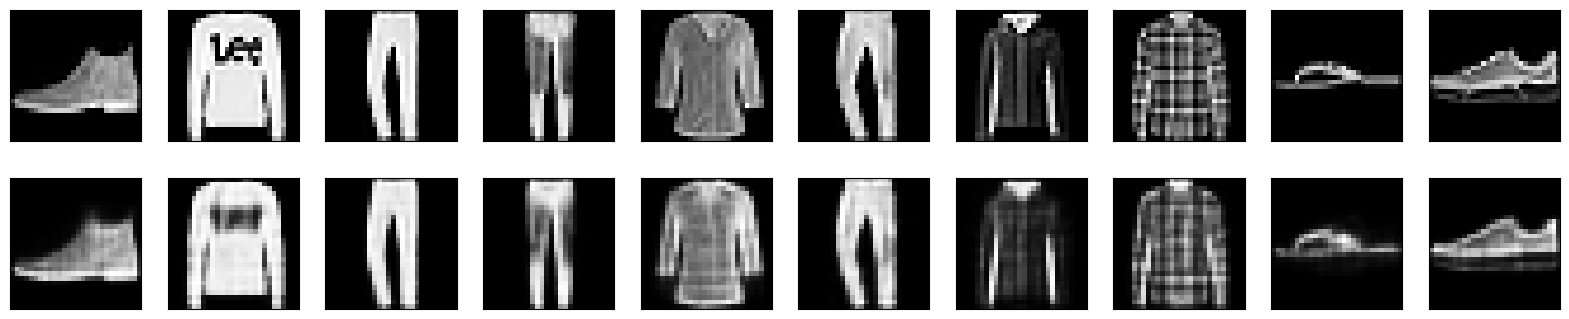

In [8]:
# 4. Visualize the reconstructed images
# Your code here

# Visualization
n = 10  # Number of images to display
plt.figure(figsize=(20, 4))
for i in range(n):
    # Original images
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Reconstructed images
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_imgs[i].reshape(28, 28), cmap='gray')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()

In [9]:
# 4. Visualize the PCA-projection of the latent space. Try to include the labels in the plot for a better understanding of 
# the distribution of the latent space.
# Your code here

# Initialize PCA to reduce to 2 components for 2D visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(decoded_imgs) # Shape: (N_samples, 2)

print(f"PCA-projected shape: {X_pca.shape}")

PCA-projected shape: (10000, 2)


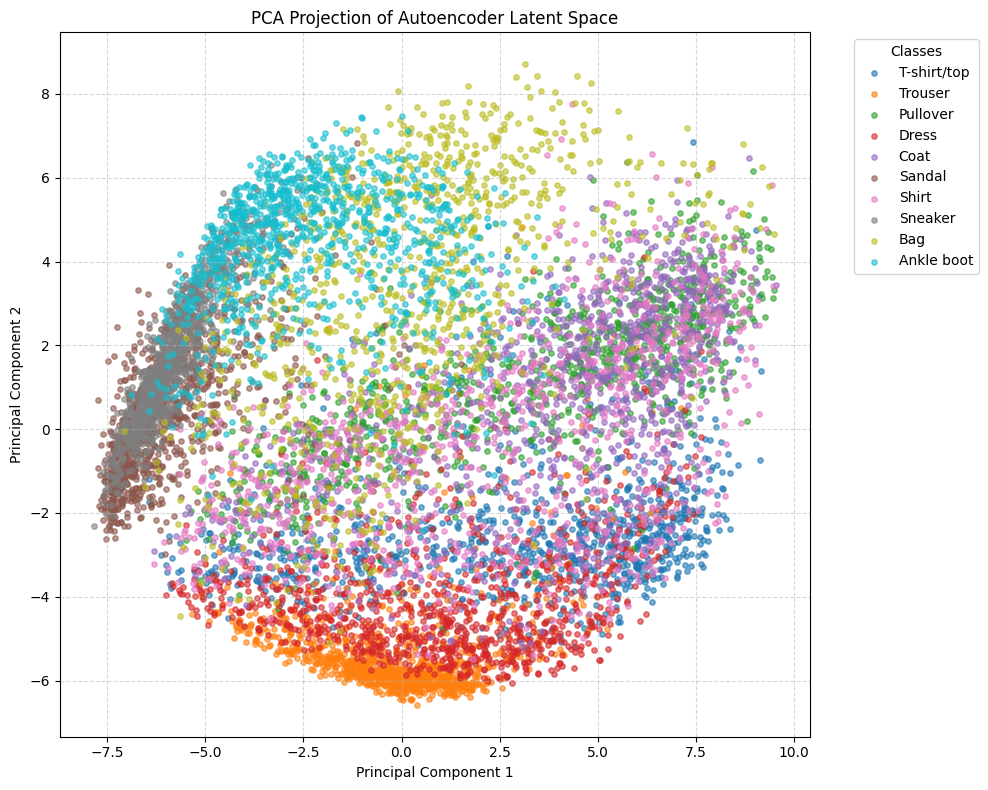

Explained variance ratio: [0.31493652 0.18766123]
Total explained variance: 0.50259775


In [10]:
# Fashion-MNIST class names
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"]

# This is just to print names in the plot instead of class numbers.
unique_classes = np.unique(y_test)
plt.figure(figsize=(10, 8))

for i in unique_classes:
    mask = (y_test == i)
    plt.scatter(
        X_pca[mask, 0], 
        X_pca[mask, 1], 
        alpha=0.6, 
        s=15,
        label=class_names[i] if i < len(class_names) else f'Class {i}')

plt.legend(title='Classes', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.title('PCA Projection of Autoencoder Latent Space')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Display the explained variance.
print(f"Explained variance ratio: {pca.explained_variance_ratio_}")
print("Total explained variance:", sum(pca.explained_variance_ratio_))

### Second model

In [11]:
# 2. Build the autoencoder model

# Encoder: compress the input image into a latent representation
encoder_input = keras.Input(shape=(28, 28))

# Flatten the image into a vector of 784 values
x = layers.Flatten()(encoder_input)

# Reduce the dimensionality
x = layers.Dense(256, activation="relu")(x)
x = layers.Dense(64, activation="relu")(x)

# Latent representation (32 dimensions)
latent = layers.Dense(32, activation="relu")(x)

# Create the encoder model
encoder = keras.Model(encoder_input, latent, name="encoder")


# Decoder: reconstruct the original image from the latent representation
decoder_input = keras.Input(shape=(32,))

x = layers.Dense(64, activation="relu")(decoder_input)
x = layers.Dense(256, activation="relu")(x)

# Reconstruct the 784 pixels
x = layers.Dense(784, activation="sigmoid")(x)

# Reshape the output into a 28x28 image
decoder_output = layers.Reshape((28, 28))(x)

# Create the decoder model
decoder = keras.Model(decoder_input, decoder_output, name="decoder")


# Combine encoder and decoder into one autoencoder
autoencoder_input = keras.Input(shape=(28, 28))
encoded = encoder(autoencoder_input)
decoded = decoder(encoded)

autoencoder_2 = keras.Model(autoencoder_input, decoded, name="autoencoder_2")

# Display model architecture
autoencoder_2.summary()

Model: "autoencoder_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 32)             │       219,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 28, 28)         │       220,240 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 439,728 (1.68 MB)

 Trainable params: 439,728 (1.68 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.3093 - val_loss: 0.3039
Epoch 2/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2985 - val_loss: 0.2985
Epoch 3/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.2936 - val_loss: 0.2936
Epoch 4/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.2901 - val_loss: 0.2906
Epoch 5/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.2877 - val_loss: 0.2893
Epoch 6/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.2857 - val_loss: 0.2869
Epoch 7/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2842 - val_loss: 0.2858
Epoch 8/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.2829 - val_loss: 0.2851
Epoch 9/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2818 - val_loss: 0.2834
Epoch 10/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.2806 - val_loss: 0.2831
Epoch 11/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.2798 - val_loss: 0.2817
Epoch 12/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step

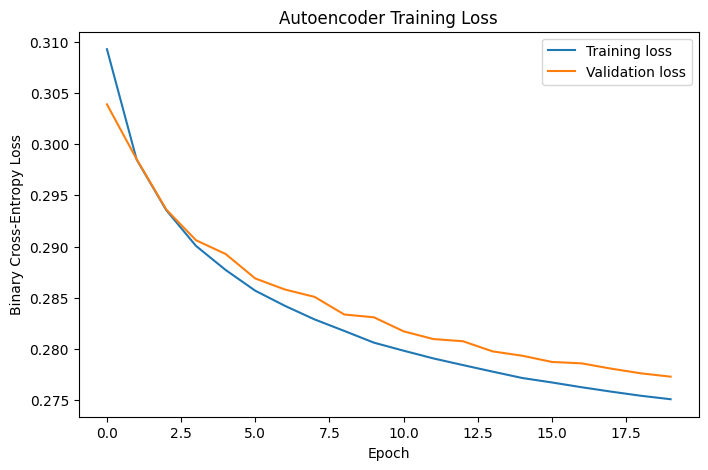

In [13]:
# 3. Compile and train the autoencoder

# Compile the model
autoencoder_2.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

# Train the autoencoder
history = autoencoder_2.fit(
    x_train_2, x_train_2,
    epochs=20,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test_2, x_test_2)
)

# Plot the training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Autoencoder Training Loss")
plt.legend()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


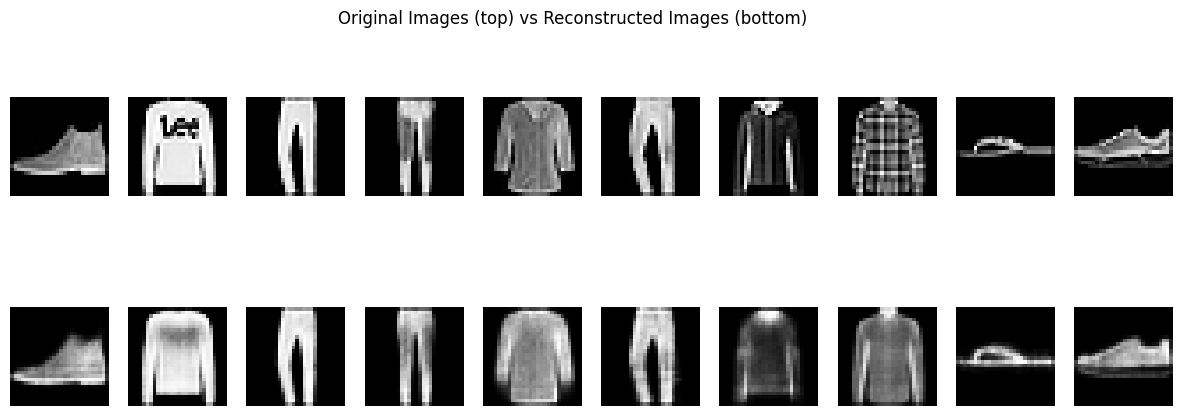

In [16]:
# 4. Visualize the reconstructed images

# Reconstruct images from the test dataset
reconstructed_images = autoencoder_2.predict(x_test_2)

# Display original and reconstructed images
plt.figure(figsize=(15, 5))

for i in range(10):

    # Original image
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test_2[i], cmap="gray")
    plt.axis("off")

    # Reconstructed image
    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed_images[i], cmap="gray")
    plt.axis("off")

plt.suptitle("Original Images (top) vs Reconstructed Images (bottom)")
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


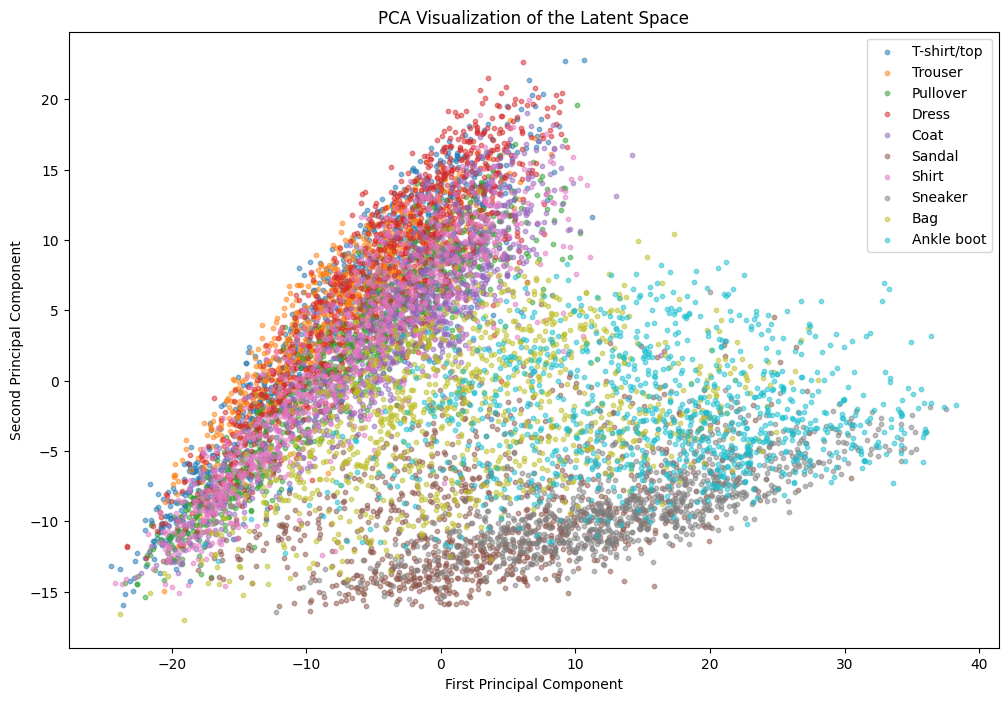

Explained variance ratio: [0.31493652 0.18766123]
Total explained variance: 0.50259775


In [18]:
# 5. Visualize the PCA-projection of the latent space. Try to include the labels in the plot for a better understanding of 
# the distribution of the latent space.

# Encoding the test images into the latent space.
latent_representations = encoder.predict(x_test_2)

# Applying PCA to reduce the latent space from 32 to 2 dimensions.
pca_2 = PCA(n_components=2)
latent_2d = pca_2.fit_transform(latent_representations)

# Fashion-MNIST class names.
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# Plotting the 2D latent space.
plt.figure(figsize=(12, 8))

for i in range(10):

    # Selecting images belonging to the current class.
    indices = y_test == i

    plt.scatter(
        latent_2d[indices, 0],
        latent_2d[indices, 1],
        label=class_names[i],
        alpha=0.5,
        s=10
    )

plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.title("PCA Visualization of the Latent Space")
plt.legend()
plt.show()

# Displaying the explained variance.
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", sum(pca.explained_variance_ratio_))

**Discussion**
1. Why do we normalize the pixel values of the images?

    We normalize pixel values between 0 and 1, this is to prevent larger values dominating the weights (typical machine learning practice). It makes training more stable and faster. It also helps the neural network learn more efficiently.

2. How does the size of the latent space affect the reconstructed images?

    Results of this can **directly** be seen in the two models above. We specifically included these models to showcase the difference between reconstruction quality and latent space organization. 

    First model is a simpler model and as seen above, it returns better quality reconstructed images. More details are preserved. However, if we look at the PCA latent space visualization, we can see that it resembles a large blob. There isn't much distinction between the classes there.
    
    Second model is a more complex model. However, it's seen above that when it comes to reconstructed image quality, it is lower fidelity than the first model. Almost none, if not all of the details are missing. Although it can be seen as the first model is better, we see the positive side of the second model in the PCA visualization. Classes are much more distinct and separated.
    Thus, it is our conclusion that even though it returns lower fidelity reconstructions, the second model would perform better in classifying in larger datasets because it is understood that it generalizes better. This is because second model latent space contains better separated classes.

3. Can autoencoders be used for noise reduction? How?

    Yes. It is one of the main areas autoencoders are used in. We can train an autoencoder using noisy images as input and clean images as targets. The model learns to remove noise and reconstruct cleaner images.

___
### **Task 2**

In contrast to simple autoencoders, which aim to learn a deterministic mapping from input data to a compressed latent space and back, **Variational Autoencoders (VAEs)** introduce a probabilistic approach to the latent space. While simple autoencoders can reconstruct data effectively, they are not inherently capable of generating new, realistic data samples. VAEs, on the other hand, are designed for _both reconstruction and generation_ of novel data samples, making them highly useful for generative modeling tasks.

**Why VAEs?** A simple autoencoder maps input data to a fixed point in the latent space, meaning that each input has a single corresponding latent vector. While this approach works well for compression and reconstruction, it lacks the ability to generalize and generate new data points because the latent space is not continuous or well-structured.

In contrast, a Variational Autoencoder treats the latent space probabilistically. Instead of mapping each input to a single point, it maps inputs to a distribution (typically a Gaussian distribution) in the latent space. This probabilistic treatment allows for the generation of new samples by sampling from the learned distribution, thus enabling the model to create *new*, unseen data points that resemble the training data.

**How VAEs Work?** In a VAE, the _encoder_ maps the input data to <u>two</u> vectors: a _mean vector_ and a _variance (or log variance) vector_ (in contrast to one as in a traditional AE). These vectors represent a Gaussian distribution in the latent space. Instead of encoding to a fixed point, the model <u>samples</u> a latent vector from this distribution, using these mean and variance parameters. This sampling introduces variability, allowing the VAE to explore different parts of the latent space and generate diverse outputs.

The _decoder_ then reconstructs the data by decoding from the sampled latent vector, which can either come from the encoded input or be randomly generated. This process makes VAEs ideal for generating novel data samples in applications like image generation.

**The loss function?** The loss function plays a crucial role in training the model to both reconstruct input data and ensure that the latent space is properly structured. The VAE loss function consists of two main components:

1. Reconstruction Loss: Measures how well the VAE is able to reconstruct the input data from the latent space. Typically, this is computed using binary cross-entropy (for normalized image data) or mean squared error (for continuous data). For images, binary cross-entropy is often used.

$$\mathcal{L}_{\text{reconstruction}}(x, \hat{x}) = - \sum_{i=1}^{N} \left[ x_i \log(\hat{x}_i) + (1 - x_i) \log(1 - \hat{x}_i) \right]$$

Where:
$x_i$  is the original data point (e.g., pixel value).
$\hat{x}_i$  is the reconstructed data point.
$N$  is the number of data points or pixels.

2. KL Divergence Loss: is used to ensure that the learned latent distribution  $q(z|x)$, parameterized by  $\mu$  and  $\sigma^2$, is close to a standard normal distribution  $p(z) = \mathcal{N}(0, I)$.

$$\mathcal{L}_{\text{KL}}(q(z|x) \parallel p(z)) = -\frac{1}{2} \sum_{j=1}^{d} \left( 1 + \log(\sigma_j^2) - \mu_j^2 - \sigma_j^2 \right)$$
Where:
 $\mu_j$  is the mean of the latent variable distribution. $\sigma_j^2$  is the variance of the latent variable distribution. $d$  is the dimensionality of the latent space.

_Total Loss Function_ The total loss function for a VAE is the sum of the reconstruction loss and the KL divergence loss:
$$\mathcal{L}_{\text{VAE}} = \mathcal{L}_{\text{reconstruction}} + \mathcal{L}_{\text{KL}}$$


**The Role of KL Divergence** A crucial aspect of training VAEs is ensuring that the latent space is well-structured and that the learned distributions align with a _prior distribution_ (typically a standard normal distribution). This is where the _Kullback-Leibler (KL) divergence loss_ comes in. KL divergence measures how different the learned distribution is from the desired prior distribution. By minimizing KL divergence during training, the VAE ensures that the latent space follows a continuous, smooth distribution, making it easier to generate realistic new samples by sampling from this space.

In summary, VAEs combine the strengths of autoencoders for reconstruction with a probabilistic latent space, enabling the generation of new data samples and ensuring smooth interpolation within the latent space through the use of KL divergence. This combination makes VAEs a powerful generative model in unsupervised learning tasks.

<div>
<img src="https://tikz.net/janosh/vae.png" width="350"/>
<div>

Run the following code

In [19]:
import numpy as np
import tensorflow as tf
import keras
from keras import layers, ops
import matplotlib.pyplot as plt

In [20]:
# Load the Fashion-MNIST dataset.
(x_train, _), (x_test, _) = keras.datasets.fashion_mnist.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
# Flatten each 28x28 image to a 784 vector
x_train = x_train.reshape((len(x_train), -1))
x_test = x_test.reshape((len(x_test), -1))

In [21]:
input_dim = x_train.shape[1]  # 784 pixels per image
latent_dim = 2  # Dimensionality of the latent space (small for simplicity, and so that we can plot it)

In [22]:
# We define the encoder in a similar way as the autoencoder
encoder_inputs = layers.Input(shape=(input_dim,))
x = layers.Dense(256, activation="relu")(encoder_inputs)

In [23]:
# However, instead of a single output layer to the latent space, we have two output layers (latent space parameters: mean (mu) and log variance (log_var))
z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)

In [24]:
# We define a sampling layer to sample from the latent space, which introduces stochasticity in the model and helps in training (as it still allows gradients to flow backwards)
# This is the reparameterization trick: z = mu + sigma * epsilon, where epsilon ~ N(0, I)
class Sampling(layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.seed_generator = keras.random.SeedGenerator(1337)

    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = ops.shape(z_mean)[0]
        dim = ops.shape(z_mean)[1]
        epsilon = keras.random.normal(shape=(batch, dim), seed=self.seed_generator)
        return z_mean + ops.exp(0.5 * z_log_var) * epsilon

In [25]:
# The Sampling layer takes the learned parameters (mean and log variance) and returns a sampled latent vector z.
# The encoder will output all three: z is passed on to the decoder, while z_mean and z_log_var are used in the loss function
z = Sampling(name="z")([z_mean, z_log_var])

In [26]:
# The decoder is defined in the same way as the autoencoder
decoder_input = layers.Input(shape=(latent_dim,))
x = layers.Dense(256, activation="relu")(decoder_input)
decoded_img = layers.Dense(input_dim, activation="sigmoid")(x)

In a Variational Autoencoder (VAE), adjusting the weight of the KL divergence loss controls the balance between data reconstruction accuracy and latent space regularization. Increasing the weight encourages a more structured and continuous latent space but may reduce reconstruction quality, while decreasing it improves reconstruction but risks losing meaningful structure in the latent space. In the code below, the total loss is $\mathcal{L}_{\text{reconstruction}} + w \cdot \mathcal{L}_{\text{KL}}$, where $w$ is `KL_weight`.

In [27]:
#KL divergence loss weight. This is a hyperparameter that can be tuned, run ALL cells below to see the effect of different values.
# This is the value you should experiment with
KL_weight = 1 # 1.0

In [28]:
# Having built our layers, we can now define the models.
# clone_model gives the models fresh (untrained) weights every time this cell is run,
# so each KL_weight experiment starts from scratch.
encoder = keras.models.clone_model(keras.Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder"))
decoder = keras.models.clone_model(keras.Model(decoder_input, decoded_img, name="decoder"))

In [29]:
# VAE model that connects the encoder and decoder, with the VAE loss: Reconstruction loss + KL divergence.
# We write our own train_step, because the loss depends on z_mean and z_log_var, not only on the input and output.
class VAE(keras.Model):
    def __init__(self, encoder, decoder, kl_weight=1.0, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.kl_weight = kl_weight
        self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def call(self, inputs):
        """Forward pass (used for inference/predict)."""
        z_mean, z_log_var, z = self.encoder(inputs)
        return self.decoder(z)

    def compute_losses(self, data):
        """Shared logic for train/test step."""
        z_mean, z_log_var, z = self.encoder(data)
        reconstruction = self.decoder(z)

        # Reconstruction loss: binary cross-entropy summed over the 784 pixels -> one value per image
        reconstruction_loss = ops.sum(
            ops.binary_crossentropy(data, reconstruction), axis=-1
        )
        # KL divergence between q(z|x) = N(mu, sigma^2) and the prior p(z) = N(0, I) -> one value per image
        kl_loss = -0.5 * ops.sum(
            1 + z_log_var - ops.square(z_mean) - ops.exp(z_log_var), axis=-1
        )
        total_loss = ops.mean(reconstruction_loss + self.kl_weight * kl_loss)
        return total_loss, reconstruction_loss, kl_loss

    def _update_metrics(self, total_loss, reconstruction_loss, kl_loss):
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

    def train_step(self, data):
        if isinstance(data, (tuple, list)):
            data = data[0]
        with tf.GradientTape() as tape:
            total_loss, reconstruction_loss, kl_loss = self.compute_losses(data)

        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        return self._update_metrics(total_loss, reconstruction_loss, kl_loss)

    def test_step(self, data):
        if isinstance(data, (tuple, list)):
            data = data[0]
        total_loss, reconstruction_loss, kl_loss = self.compute_losses(data)
        return self._update_metrics(total_loss, reconstruction_loss, kl_loss)

In [ ]:
# Train the VAE.
vae = VAE(encoder, decoder, kl_weight=KL_weight)
vae.compile(optimizer=keras.optimizers.Adam())

history = vae.fit(x_train, epochs=20, batch_size=128, validation_data=(x_test,), verbose=2)

Epoch 1/20
469/469 - 4s - 9ms/step - kl_loss: 9.2462 - loss: 308.3814 - reconstruction_loss: 299.1342 - val_kl_loss: 6.6371 - val_loss: 284.2749 - val_reconstruction_loss: 277.7002
Epoch 2/20
469/469 - 3s - 6ms/step - kl_loss: 6.3920 - loss: 280.4375 - reconstruction_loss: 274.0458 - val_kl_loss: 6.3432 - val_loss: 278.9966 - val_reconstruction_loss: 272.6900
Epoch 3/20
469/469 - 3s - 6ms/step - kl_loss: 6.2529 - loss: 276.0444 - reconstruction_loss: 269.8047 - val_kl_loss: 6.2308 - val_loss: 275.5292 - val_reconstruction_loss: 269.3593
Epoch 4/20
469/469 - 3s - 6ms/step - kl_loss: 6.2687 - loss: 273.3138 - reconstruction_loss: 267.0421 - val_kl_loss: 6.5833 - val_loss: 273.5714 - val_reconstruction_loss: 267.0713
Epoch 5/20
469/469 - 3s - 6ms/step - kl_loss: 6.2582 - loss: 271.4808 - reconstruction_loss: 265.2235 - val_kl_loss: 6.4006 - val_loss: 272.1310 - val_reconstruction_loss: 265.8146
Epoch 6/20
469/469 - 3s - 6ms/step - kl_loss: 6.2301 - loss: 270.0782 - reconstruction_loss: 26

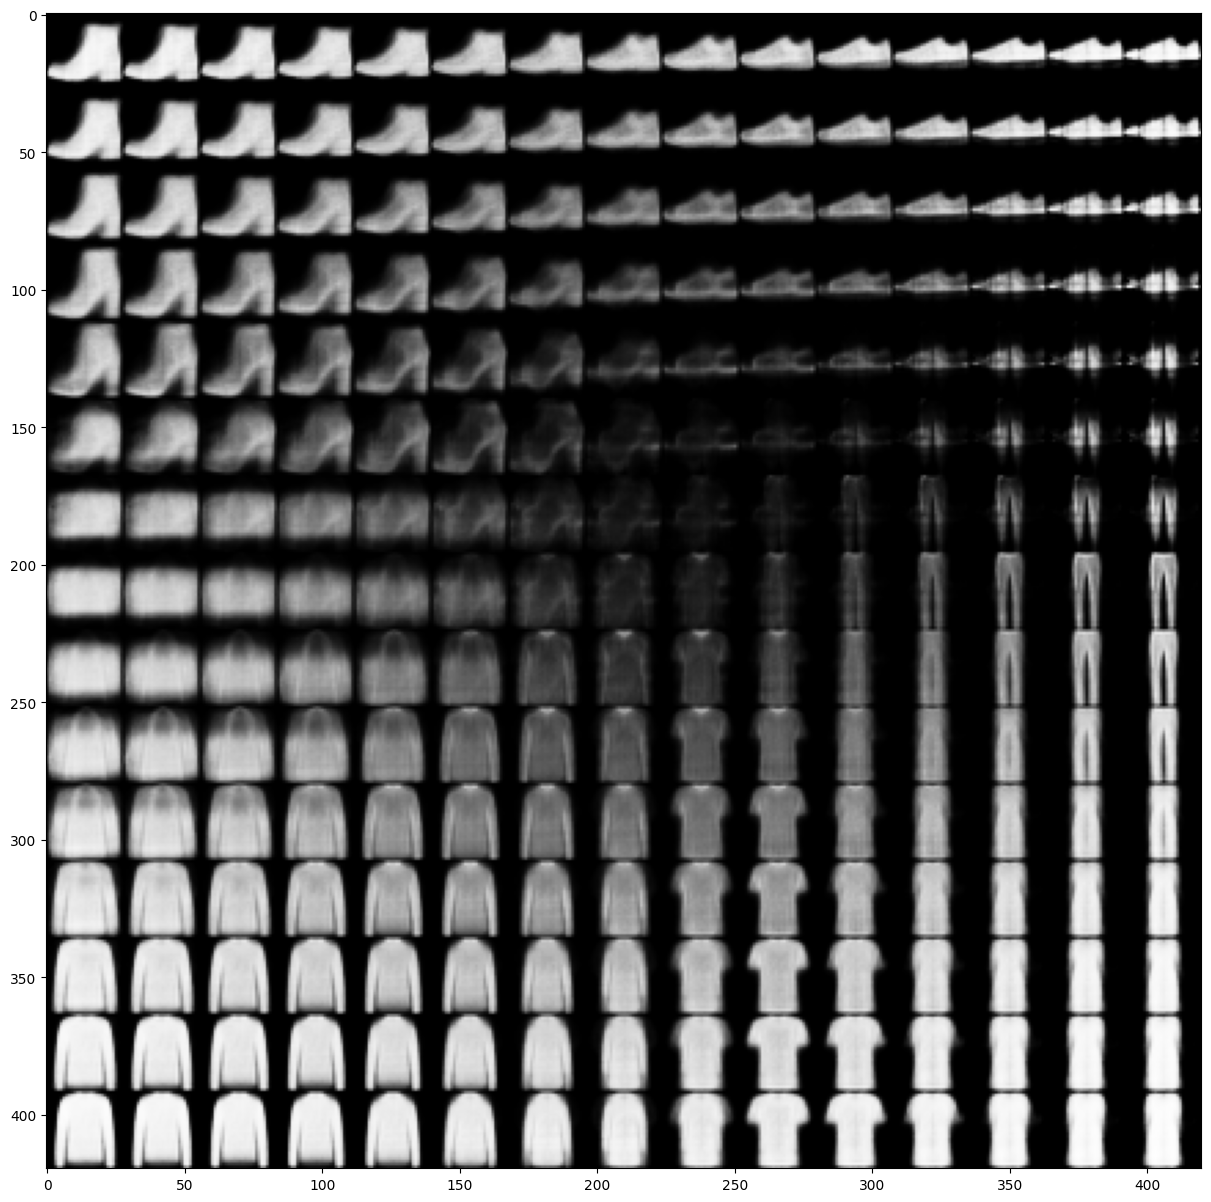

In [31]:
# Run this visualisation code after training the VAE to answer the discussion questions.
def plot_latent_space(decoder, n=15, figsize=15):
    """Plots a grid of clothing items decoded from the VAE's latent space."""
    scale = 2.0
    figure = np.zeros((28 * n, 28 * n))
    grid_x = np.linspace(-scale, scale, n)
    grid_y = np.linspace(-scale, scale, n)

    # Decode all n*n grid points in a single call (much faster than one predict per point)
    z_samples = np.array([[xi, yi] for yi in grid_y for xi in grid_x], dtype="float32")
    x_decoded = decoder.predict(z_samples, verbose=0)

    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):
            item = x_decoded[i * n + j].reshape(28, 28)
            figure[i * 28: (i + 1) * 28, j * 28: (j + 1) * 28] = item

    plt.figure(figsize=(figsize, figsize))
    plt.imshow(figure, cmap='Greys_r')
    plt.show()

# Plot latent space
plot_latent_space(decoder)

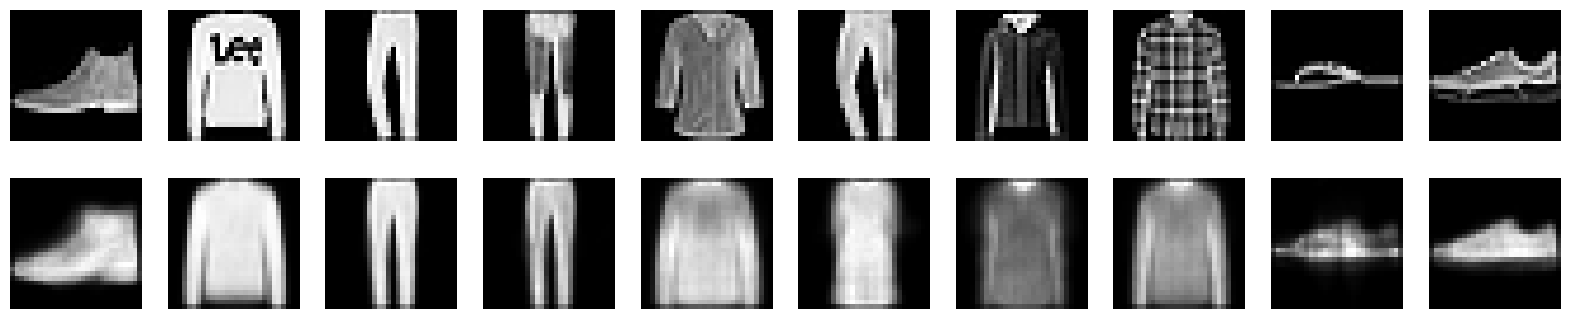

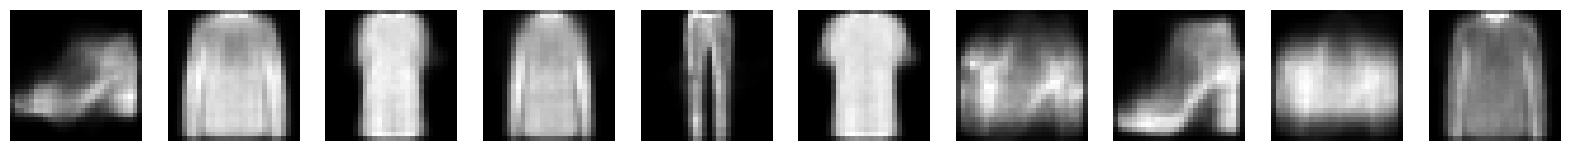

In [32]:
# Run this code to compare original and reconstructed images (top: original, bottom: reconstructed),
# and to generate new images by decoding random points sampled from the prior N(0, I).
test_z_mean, _, _ = vae.encoder.predict(x_test, verbose=0)  # the mean of q(z|x) gives clean, deterministic reconstructions
decoded_imgs = vae.decoder.predict(test_z_mean, verbose=0)

n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
    # Original
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    ax.axis("off")

    # Reconstructed
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_imgs[i].reshape(28, 28), cmap="gray")
    ax.axis("off")
plt.show()

# Sample new random images
random_latent_vectors = np.random.normal(size=(n, latent_dim)).astype("float32")
generated_images = vae.decoder.predict(random_latent_vectors, verbose=0)

plt.figure(figsize=(20, 2))
for i in range(n):
    ax = plt.subplot(1, n, i + 1)
    plt.imshow(generated_images[i].reshape(28, 28), cmap="gray")
    ax.axis("off")
plt.show()

**Discussion**

Tips: refer to the visualizations above and the loss output from your training cell (make sure verbose is set to 1 or 2) to answer the questions.

1. Adjust the weight of the KL divergence term in the VAE loss function (e.g., set it to 0.1, 1, and 5). Run the model with each weight setting and observe the results.
2. Based on your observations, discuss how each change in the KL weight affected the VAE’s performance. Were the effects consistent with your expectations, and why or why not? Consider both the quality of the reconstructions, the loss values, and the continuity of the latent space in your answer.

- KL weight = 0.1: The model produces good reconstructions with recognizable details. However, the latent space is less regularized. Total loss = 254.
- KL weight = 1: The latent space becomes more regularized, but the reconstruction quality decreases slightly. Total loss = 263.
- KL weight = 5: The model produces less accurate and sometimes blurrier reconstructions. The latent space is more regularized, but some generated images are less clear. Total loss = 283.

    Overall, the results match our expectations. Increasing the KL weight reduces the KL loss (12.78 to 4.10) but increases the reconstruction loss (253 to 263). This shows the trade-off between reconstruction quality and latent space regularization. A higher KL weight encourages a more continuous latent space, but can make image reconstruction less accurate.

___